In [1]:
import os

folder_path = r"C:\Users\DELL\Downloads\superstore_sales"

print(os.listdir(folder_path))

['superstore_sales.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r"C:\Users\DELL\Downloads\superstore_sales\superstore_sales.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (9994, 9)


In [3]:
print("Total Duplicate Rows:")
print(df.duplicated().sum())

Total Duplicate Rows:
2


In [4]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Before removing duplicates: (9994, 9)
After removing duplicates: (9992, 9)
Remaining duplicates: 0


In [5]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    format='%m/%d/%Y'
)

print("Order Date converted successfully!")
print(df['Order Date'].dtype)
print(df[['Order Date']].head())

Order Date converted successfully!
datetime64[us]
  Order Date
0 2016-11-08
1 2016-11-08
2 2016-06-12
3 2015-10-11
4 2015-10-11


In [6]:
df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Month_Name'] = df['Order Date'].dt.month_name()

print("Year and Month columns created!")

df[['Order Date', 'Year', 'Month', 'Month_Name']].head()

Year and Month columns created!


,Order Date,Year,Month,Month_Name
0,2016-11-08,2016,11,November
1,2016-11-08,2016,11,November
2,2016-06-12,2016,6,June
3,2015-10-11,2015,10,October
4,2015-10-11,2015,10,October


In [7]:
print("========== RETAIL SALES SUMMARY ==========")

print("Total Sales:", round(df['Sales'].sum(), 2))

print("Total Profit:", round(df['Profit'].sum(), 2))

print("Total Quantity Sold:", df['Quantity'].sum())

print("Average Sales:", round(df['Sales'].mean(), 2))

print("Average Profit:", round(df['Profit'].mean(), 2))

========== RETAIL SALES SUMMARY ==========
Total Sales: 2296914.56
Total Profit: 286408.34
Total Quantity Sold: 37869
Average Sales: 229.88
Average Profit: 28.66


In [8]:
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

print("========== REGION-WISE SALES ==========")
print(region_sales)

========== REGION-WISE SALES ==========
Region
West       725457.8245
East       678499.8680
Central    501239.8908
South      391716.9770
Name: Sales, dtype: float64


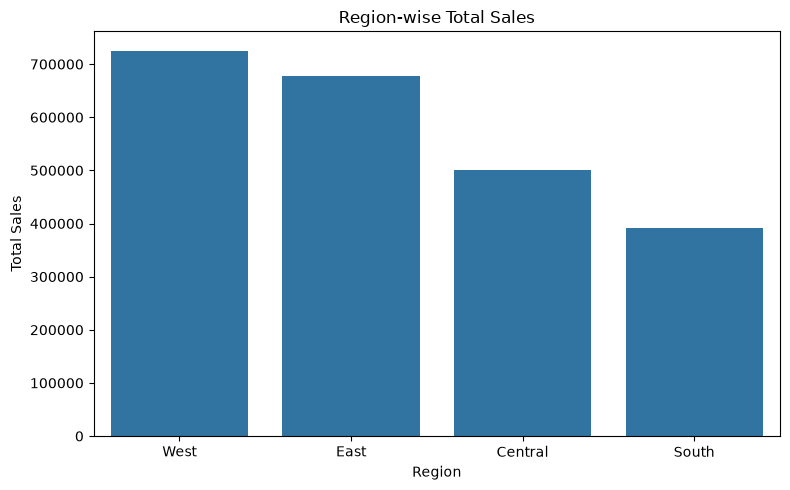

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title('Region-wise Total Sales')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.tight_layout()

plt.savefig('region_wise_sales.png', dpi=300)
plt.show()

In [10]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

print("========== CATEGORY-WISE SALES ==========")
print(category_sales)

========== CATEGORY-WISE SALES ==========
Category
Technology         836154.0330
Furniture          741713.4953
Office Supplies    719047.0320
Name: Sales, dtype: float64


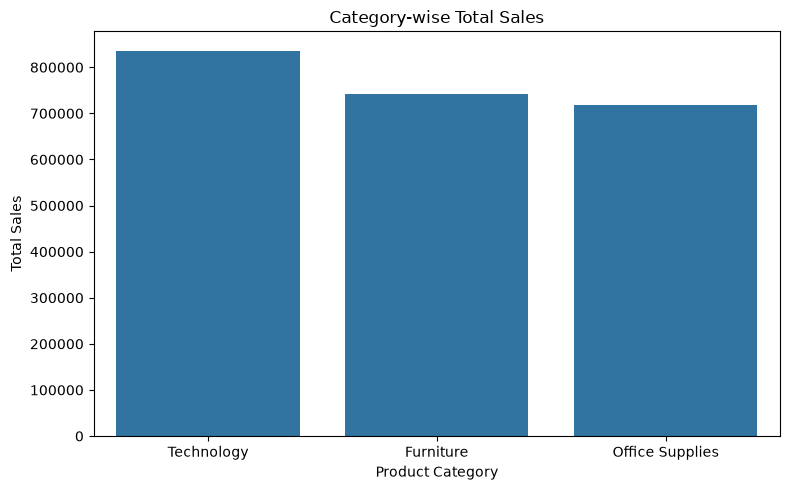

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Category-wise Total Sales')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.tight_layout()

plt.savefig('category_wise_sales.png', dpi=300)
plt.show()

In [12]:
subcategory_sales = (
    df.groupby('Sub-Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("========== TOP 10 SUB-CATEGORIES ==========")
print(subcategory_sales.head(10))

========== TOP 10 SUB-CATEGORIES ==========
Sub-Category
Phones         330007.0540
Chairs         328167.7310
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Name: Sales, dtype: float64


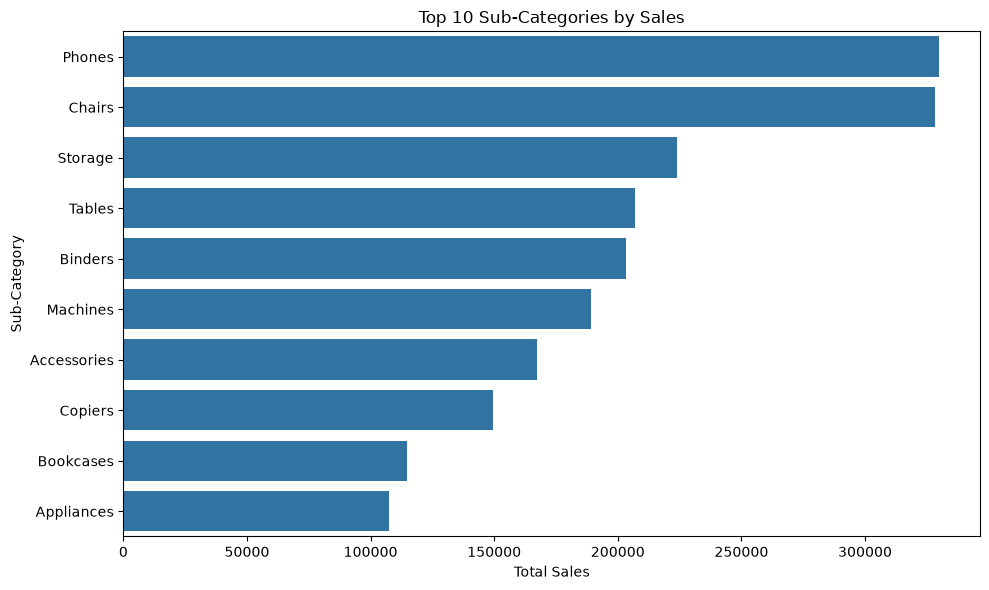

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=subcategory_sales.head(10).values,
    y=subcategory_sales.head(10).index
)

plt.title('Top 10 Sub-Categories by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Sub-Category')
plt.tight_layout()

plt.savefig('top_10_subcategories.png', dpi=300)
plt.show()

In [14]:
category_profit = (
    df.groupby('Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("========== CATEGORY-WISE PROFIT ==========")
print(category_profit)


========== CATEGORY-WISE PROFIT ==========
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18462.5924
Name: Profit, dtype: float64


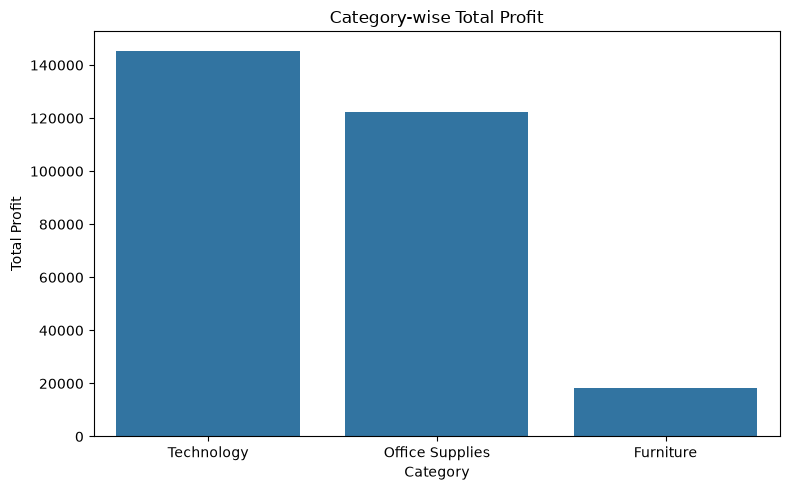

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title('Category-wise Total Profit')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.tight_layout()

plt.savefig('category_wise_profit.png', dpi=300)
plt.show()


In [16]:
profitable_orders = (df['Profit'] > 0).sum()
loss_orders = (df['Profit'] < 0).sum()
zero_profit_orders = (df['Profit'] == 0).sum()

print("========== PROFIT AND LOSS ANALYSIS ==========")

print("Profitable Records:", profitable_orders)
print("Loss Records:", loss_orders)
print("Zero Profit Records:", zero_profit_orders)

========== PROFIT AND LOSS ANALYSIS ==========
Profitable Records: 8057
Loss Records: 1870
Zero Profit Records: 65


In [18]:
subcategory_profit = (
    df.groupby('Sub-Category')['Profit']
    .sum()
    .sort_values()
)

print("========== SUB-CATEGORY PROFIT ==========")
print(subcategory_profit)

print("\nTop 5 Loss-Making Sub-Categories:")
print(subcategory_profit.head(5))



========== SUB-CATEGORY PROFIT ==========
Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13058.4044
Appliances     18138.0054
Storage        21278.8264
Chairs         26602.2251
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64

Top 5 Loss-Making Sub-Categories:
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Fasteners      949.5182
Machines      3384.7569
Name: Profit, dtype: float64


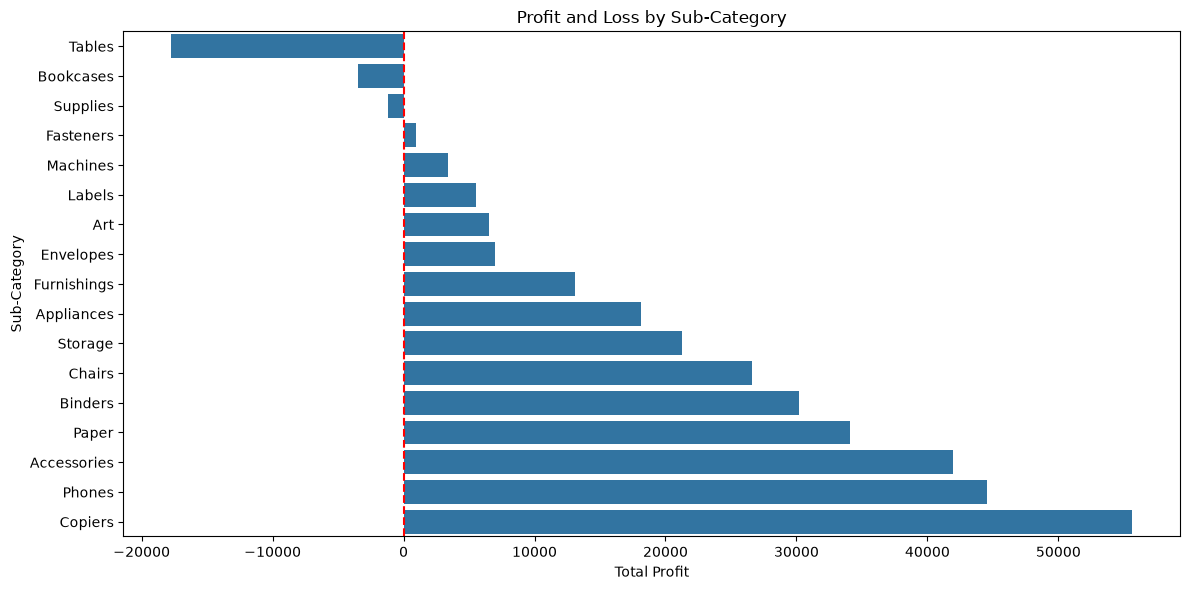

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=subcategory_profit.values,
    y=subcategory_profit.index
)

plt.axvline(x=0, color='red', linestyle='--')

plt.title('Profit and Loss by Sub-Category')
plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')

plt.tight_layout()
plt.savefig('subcategory_profit_analysis.png', dpi=300)
plt.show()

In [20]:
monthly_sales = (
    df.groupby('Month_Name')['Sales']
    .sum()
)

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

print("========== MONTHLY SALES ==========")
print(monthly_sales)

========== MONTHLY SALES ==========
Month_Name
January       94924.8356
February      59751.2514
March        205005.4888
April        137480.7566
May          155028.8117
June         152718.6793
July         147233.1690
August       159044.0630
September    307649.9457
October      200322.9847
November     352461.0710
December     325293.5035
Name: Sales, dtype: float64


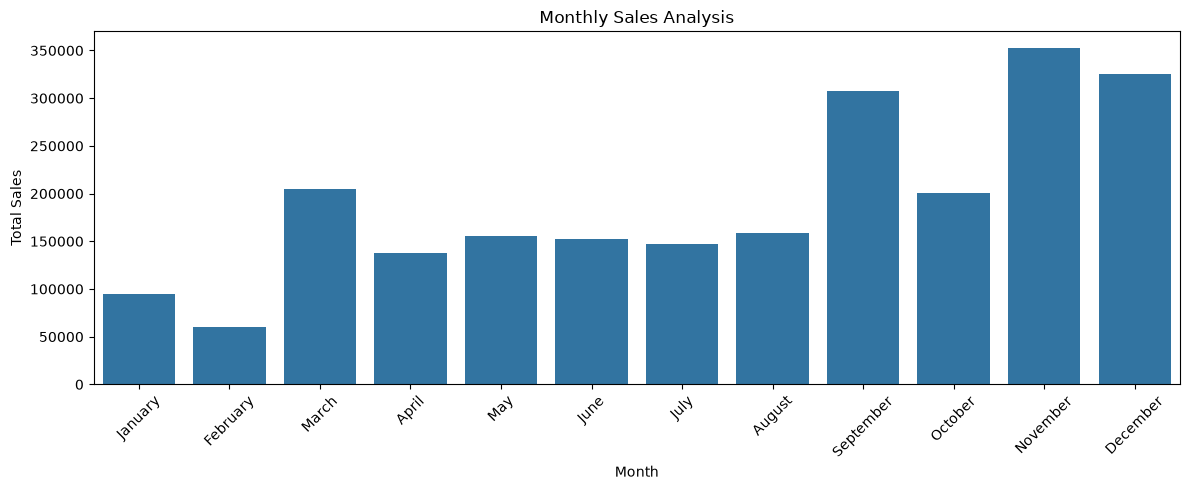

In [21]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values
)

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('monthly_sales_analysis.png', dpi=300)
plt.show()

In [22]:
yearly_sales = (
    df.groupby('Year')['Sales']
    .sum()
    .sort_index()
)

print("========== YEAR-WISE SALES ==========")
print(yearly_sales)


========== YEAR-WISE SALES ==========
Year
2014    483966.1261
2015    470527.5810
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


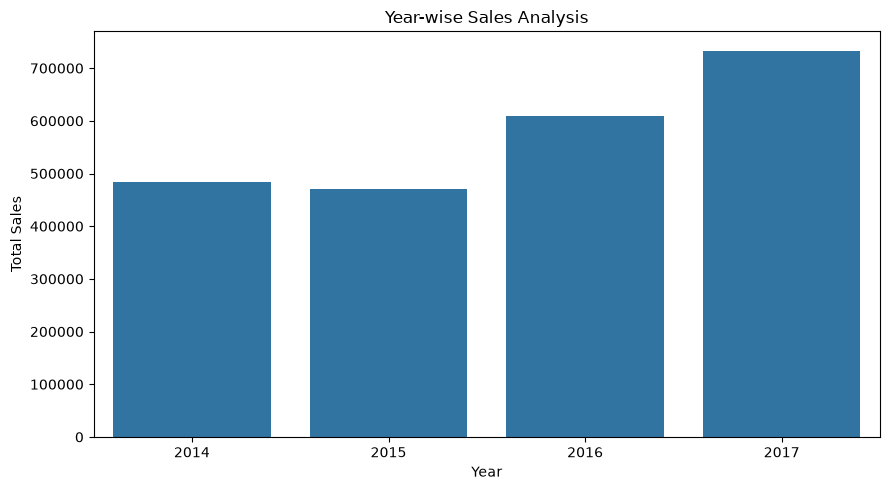

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=yearly_sales.index,
    y=yearly_sales.values
)

plt.title('Year-wise Sales Analysis')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.savefig('yearly_sales_analysis.png', dpi=300)
plt.show()

In [24]:
segment_sales = (
    df.groupby('Segment')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("========== CUSTOMER SEGMENT SALES ==========")
print(segment_sales)

========== CUSTOMER SEGMENT SALES ==========
Segment
Consumer       1.161401e+06
Corporate      7.061414e+05
Home Office    4.293718e+05
Name: Sales, dtype: float64


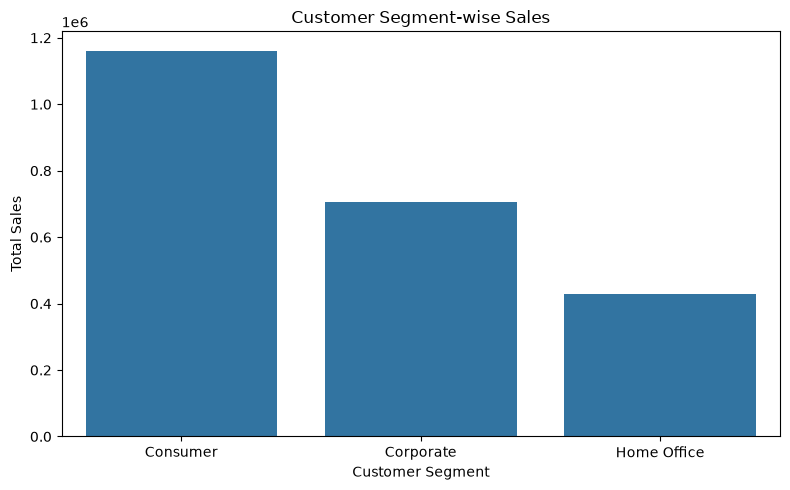

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values
)

plt.title('Customer Segment-wise Sales')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.savefig('customer_segment_sales.png', dpi=300)
plt.show()

In [26]:
segment_profit = (
    df.groupby('Segment')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print("========== CUSTOMER SEGMENT PROFIT ==========")
print(segment_profit)

========== CUSTOMER SEGMENT PROFIT ==========
Segment
Consumer       134119.2092
Corporate       91978.3948
Home Office     60310.7373
Name: Profit, dtype: float64


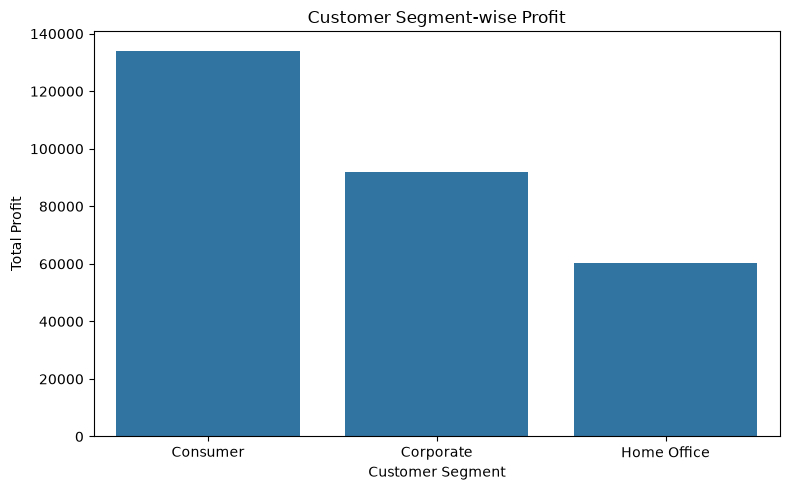

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_profit.index,
    y=segment_profit.values
)

plt.title('Customer Segment-wise Profit')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.savefig('customer_segment_profit.png', dpi=300)
plt.show()

In [28]:
print("========== RETAIL SALES PROJECT INSIGHTS ==========")

print("\n1. Total Sales:", round(df['Sales'].sum(), 2))

print("2. Total Profit:", round(df['Profit'].sum(), 2))

print("3. Total Quantity:", df['Quantity'].sum())

print("\n4. Highest Sales Region:")
print(region_sales.idxmax())

print("\n5. Highest Sales Category:")
print(category_sales.idxmax())

print("\n6. Highest Profit Category:")
print(category_profit.idxmax())

print("\n7. Highest Sales Month:")
print(monthly_sales.idxmax())

print("\n8. Highest Sales Year:")
print(yearly_sales.idxmax())

print("\n9. Highest Sales Customer Segment:")
print(segment_sales.idxmax())

print("\n10. Highest Profit Customer Segment:")
print(segment_profit.idxmax())

print("\n========== ANALYSIS COMPLETED ==========")

========== RETAIL SALES PROJECT INSIGHTS ==========

1. Total Sales: 2296914.56
2. Total Profit: 286408.34
3. Total Quantity: 37869

4. Highest Sales Region:
West

5. Highest Sales Category:
Technology

6. Highest Profit Category:
Technology

7. Highest Sales Month:
November

8. Highest Sales Year:
2017

9. Highest Sales Customer Segment:
Consumer

10. Highest Profit Customer Segment:
Consumer

========== ANALYSIS COMPLETED ==========


In [29]:
df.to_csv(
    "retail_sales_cleaned.csv",
    index=False
)

print("Retail dataset saved successfully!")
print("Final Shape:", df.shape)

Retail dataset saved successfully!
Final Shape: (9992, 12)


In [30]:
import os

print("========== FINAL PROJECT FILES ==========")

for file in os.listdir():
    if file.endswith(('.csv', '.png', '.ipynb')):
        print(file)

========== FINAL PROJECT FILES ==========
01_Customer_Churn_Prediction.ipynb
01_Retail_Sales_EDA.ipynb
accuracy_recall_comparison.png
category_wise_profit.png
category_wise_sales.png
cleaned_customer_churn.csv
content_added_by_year.png
content_by_release_year.png
content_ratings.png
correlation_heatmap.png
customer_segment_profit.png
customer_segment_sales.png
monthly_sales_analysis.png
movies_tvshows_by_year.png
movies_vs_tvshows.png
movie_duration_distribution.png
netflix_cleaned_eda.csv
netflix_cleaned_eda.ipynb
region_wise_sales.png
Retail_Sales_Analysis 01.ipynb
Retail_Sales_Analysis.ipynb
retail_sales_cleaned.csv
subcategory_profit_analysis.png
top_10_countries.png
top_10_subcategories.png
tv_show_seasons.png
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb
yearly_sales_analysis.png
